# Assignment 1 - Building a Vision Model with Keras

In this assignment, you will build a simple vision model using Keras. The goal is to classify images from the Fashion MNIST dataset, which contains images of clothing items.

You will:
1. Load and inspect the Fashion MNIST dataset.
2. Run a simple baseline model to establish a performance benchmark.
3. Build and evaluate a simple CNN model, choosing appropriate loss and metrics.
4. Design and run controlled experiments on one hyperparameter (e.g., number of filters, kernel size, etc.) and one regularization technique (e.g., dropout, L2 regularization).
5. Analyze the results and visualize the model's performance.

# 1. Loading and Inspecting the Dataset

Fashion MNIST is a dataset of grayscale images of clothing items, with 10 classes. Each image is 28x28 pixels, like the MNIST dataset of handwritten digits. Keras provides a convenient way to load this dataset. 

In this section, you should:

- [ ] Inspect the shapes of the training and test sets to confirm their size and structure.
- [ ] Convert the labels to one-hot encoded format if necessary. (There is a utility function in Keras for this.)
- [ ] Visualize a few images from the dataset to understand what the data looks like.

In [1]:
from tensorflow.keras.datasets import fashion_mnist
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Normalize the pixel values to be between 0 and 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Classes in the Fashion MNIST dataset
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [4]:
# Inspect the shapes of the datasets
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

# Convert labels to one-hot encoding
from tensorflow.keras.utils import to_categorical
y_train_cat = to_categorical(y_train, num_classes=10)
y_test_cat = to_categorical(y_test, num_classes=10)

print("Original label:", y_train[0])
print("One-hot label:", y_train_cat[0])
print("Shape:", y_train_cat.shape)


X_train shape: (60000, 28, 28)
y_train shape: (60000,)
X_test shape: (10000, 28, 28)
y_test shape: (10000,)
Original label: 9
One-hot label: [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
Shape: (60000, 10)


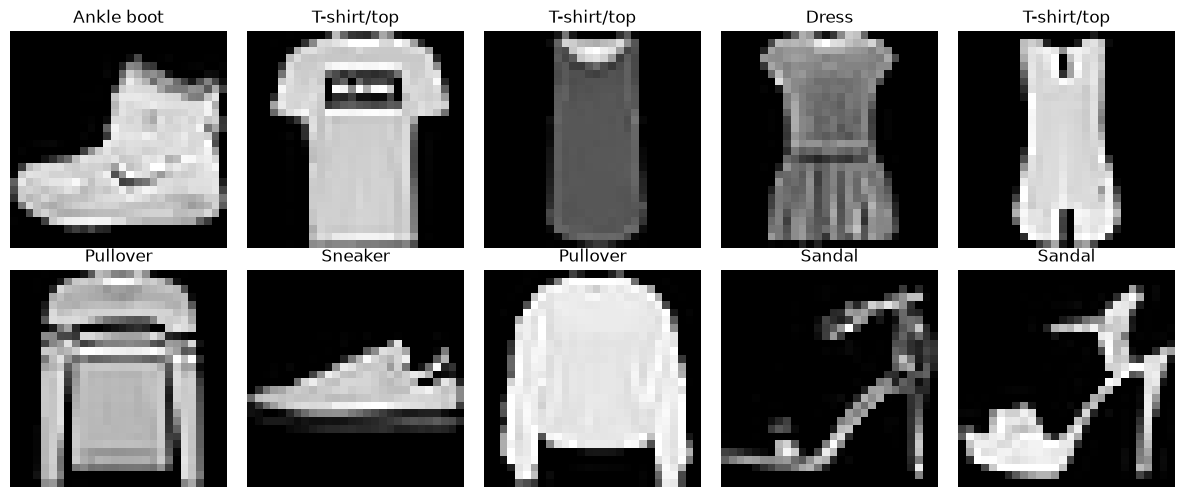

In [5]:
import matplotlib.pyplot as plt
# Verify the data looks as expected
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()

Reflection: Does the data look as expected? How is the quality of the images? Are there any issues with the dataset that you notice?

**The images look as expected, and most clothing items are recognizable despite their low resolution. However, some images are blurry, and it may be difficult to distinguish between similar categories, such as shirts, T-shirts, and pullovers. Since the images are grayscale and only 28 × 28 pixels, some details are missing. I think this could make classification more challenging for the model, especially for clothing items with similar shapes.**

# 2. Baseline Model

In this section, you will create a linear regression model as a baseline. This model will not use any convolutional layers, but it will help you understand the performance of a simple model on this dataset.
You should:
- [ ] Create a simple linear regression model using Keras.
- [ ] Compile the model with an appropriate loss function and optimizer.
- [ ] Train the model on the training set and evaluate it on the test set.

A linear regression model can be created using the `Sequential` API in Keras. Using a single `Dense` layer with no activation function is equivalent to a simple linear regression model. Make sure that the number of units in the output layer matches the number of classes in the dataset.

Note that for this step, we will need to use `Flatten` to convert the 2D images into 1D vectors before passing them to the model. Put a `Flatten()` layer as the first layer in your model so that the 2D image data can be flattened into 1D vectors.

In [9]:
from keras.models import Sequential
from keras.layers import Input, Dense, Flatten
from keras.losses import CategoricalCrossentropy

# Create a linear model
model = Sequential()

model.add(Input(shape=(28, 28)))
model.add(Flatten())
model.add(Dense(10))

# Compile the model
model.compile(
    optimizer='adam',
    loss=CategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

# Train the model
history_baseline = model.fit(
    X_train,
    y_train_cat,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

# Evaluate the model
baseline_loss, baseline_accuracy = model.evaluate(
    X_test,
    y_test_cat
)

print(f"Baseline test loss: {baseline_loss:.3f}")
print(f"Baseline test accuracy: {baseline_accuracy * 100:.2f}%")

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7755 - loss: 0.6749 - val_accuracy: 0.8268 - val_loss: 0.5086
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8349 - loss: 0.4893 - val_accuracy: 0.8378 - val_loss: 0.4651
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8441 - loss: 0.4558 - val_accuracy: 0.8467 - val_loss: 0.4465
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8501 - loss: 0.4374 - val_accuracy: 0.8463 - val_loss: 0.4398
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8549 - loss: 0.4262 - val_accuracy: 0.8528 - val_loss: 0.4247
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8572 - loss: 0.4173 - val_accuracy: 0.8532 - val_loss: 0.4241
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8580 - loss: 0.4121 - val_accuracy: 0.8500 - val_loss: 0.4252
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8599 - loss: 0.4071 - val_accuracy: 0.

Reflection: What is the performance of the baseline model? How does it compare to what you expected? Why do you think the performance is at this level?

**The baseline model achieved 84.14% test accuracy with a loss of 0.456. I think this is a reasonably good performance for such a simple model, since it only uses a Flatten layer and one Dense layer without any activation function. However, flattening the images removes their explicit spatial structure, and the model cannot learn complex nonlinear patterns. This may limit its ability to distinguish similar clothing categories, such as shirts, T-shirts, and pullovers. I expect a CNN to perform better because it can learn spatial features directly from the images.**

# 3. Building and Evaluating a Simple CNN Model

In this section, you will build a simple Convolutional Neural Network (CNN) model using Keras. A convolutional neural network is a type of deep learning model that is particularly effective for image classification tasks. Unlike the basic neural networks we have built in the labs, CNNs can accept images as input without needing to flatten them into vectors.

You should:
- [ ] Build a simple CNN model with at least one convolutional layer (to learn spatial hierarchies in images) and one fully connected layer (to make predictions).
- [ ] Compile the model with an appropriate loss function and metrics for a multi-class classification problem.
- [ ] Train the model on the training set and evaluate it on the test set.

Convolutional layers are designed to accept inputs with three dimensions: height, width and channels (e.g., RGB for color images). For grayscale images like those in Fashion MNIST, the input shape will be (28, 28, 1).

When you progress from the convolutional layers to the fully connected layers, you will need to flatten the output of the convolutional layers. This can be done using the `Flatten` layer in Keras, which doesn't require any parameters.

In [15]:
from keras.layers import Conv2D
from keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense
# Reshape the data to include the channel dimension
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# Create a simple CNN model
cnn_model = Sequential()

cnn_model.add(Input(shape=(28, 28, 1)))

cnn_model.add(Conv2D(
    filters=16,
    kernel_size=(3, 3),
    activation='relu',
    padding='same'
))

cnn_model.add(MaxPooling2D(pool_size=(2, 2)))

cnn_model.add(Flatten())
cnn_model.add(Dense(32, activation='relu'))
cnn_model.add(Dense(10, activation='softmax'))

cnn_model.summary()
# Compile the CNN
cnn_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
# Train the model
# Train the CNN
history_cnn = cnn_model.fit(
    X_train,
    y_train_cat,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)
# Evaluate the model
cnn_loss, cnn_accuracy = cnn_model.evaluate(
    X_test,
    y_test_cat
)

print(f"CNN test loss: {cnn_loss:.3f}")
print(f"CNN test accuracy: {cnn_accuracy * 100:.2f}%")


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │       100,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,874 (394.04 KB)

 Trainable params: 100,874 (394.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 14ms/step - accuracy: 0.8232 - loss: 0.5080 - val_accuracy: 0.8677 - val_loss: 0.3682
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.8788 - loss: 0.3440 - val_accuracy: 0.8862 - val_loss: 0.3195
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.8939 - loss: 0.3006 - val_accuracy: 0.8980 - val_loss: 0.2928
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.9021 - loss: 0.2761 - val_accuracy: 0.8963 - val_loss: 0.2864
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.9078 - loss: 0.2546 - val_accuracy: 0.9010 - val_loss: 0.2788
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.9134 - loss: 0.2383 - val_accuracy: 0.9057 - val_loss: 0.2669
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.9181 - loss: 0.2250 - val_accuracy: 0.9065 - val_loss: 0.2598
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.9239 - loss: 0.2117 - 

In [16]:
print(f"Baseline accuracy: {baseline_accuracy * 100:.2f}%")
print(f"CNN accuracy: {cnn_accuracy * 100:.2f}%")

improvement = (cnn_accuracy - baseline_accuracy) * 100

print(f"Accuracy difference: {improvement:.2f} percentage points")

Baseline accuracy: 84.14%
CNN accuracy: 90.23%
Accuracy difference: 6.09 percentage points


Reflection: Did the CNN model perform better than the baseline model? If so, by how much? What do you think contributed to this improvement?

**Yes, the CNN performed better than the baseline model. The test accuracy increased from 84.14% to 90.23%, an improvement of 6.09 percentage points.

I think this improvement is mainly because the convolutional layer can learn spatial features, such as edges, shapes, and patterns, from the images. Unlike the baseline model, which immediately flattens the images, the CNN processes the spatial structure before flattening.**

# 3. Designing and Running Controlled Experiments

In this section, you will design and run controlled experiments to improve the model's performance. You will focus on one hyperparameter and one regularization technique.
You should:
- [ ] Choose one hyperparameter to experiment with (e.g., number of filters, kernel size, number of layers, etc.) and one regularization technique (e.g., dropout, L2 regularization). For your hyperparameter, you should choose at least three different values to test (but there is no upper limit). For your regularization technique, simply test the presence or absence of the technique.
- [ ] Run experiments by modifying the model architecture or hyperparameters, and evaluate the performance of each model on the test set.
- [ ] Record the results of your experiments, including the test accuracy and any other relevant metrics.
- [ ] Visualize the results of your experiments using plots or tables to compare the performance of different models.

The best way to run your experiments is to create a `for` loop that iterates over a range of values for the hyperparameter you are testing. For example, if you are testing different numbers of filters, you can create a loop that runs the model with 32, 64, and 128 filters. Within the loop, you can compile and train the model, then evaluate it on the test set. After each iteration, you can store the results in a list or a dictionary for later analysis.

Note: It's critical that you re-initialize the model (by creating a new instance of the model) before each experiment. If you don't, the model will retain the weights from the previous experiment, which can lead to misleading results.

In [17]:
# A. Test Hyperparameters
import tensorflow as tf

def build_cnn(n_filters=16):

    model = Sequential()

    model.add(Conv2D(
        filters=n_filters,
        kernel_size=(3, 3),
        activation='relu',
        padding='same',
        input_shape=(28, 28, 1)
    ))

    model.add(MaxPooling2D(pool_size=(2, 2)))
    model.add(Flatten())
    model.add(Dense(32, activation='relu'))
    model.add(Dense(10, activation='softmax'))

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [18]:
#compare different numbers of convolutional filters

filter_results = []

for n_filters in [8, 16, 32]:

    tf.keras.utils.set_random_seed(42)

    model = build_cnn(n_filters)

    history = model.fit(
        X_train,
        y_train_cat,
        epochs=10,
        batch_size=64,
        validation_split=0.1,
        verbose=0
    )

    test_loss, test_accuracy = model.evaluate(
        X_test,
        y_test_cat,
        verbose=0
    )

    filter_results.append({
        'filters': n_filters,
        'validation_accuracy': max(history.history['val_accuracy']),
        'test_accuracy': test_accuracy,
        'test_loss': test_loss
    })

    print(f"Filters: {n_filters}")
    print(f"Test accuracy: {test_accuracy * 100:.2f}%")
    print(f"Test loss: {test_loss:.3f}")
    print()

c:\Users\Sadrsar1\deep_learning\deep-learning-env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Filters: 8
Test accuracy: 89.98%
Test loss: 0.284

Filters: 16
Test accuracy: 90.28%
Test loss: 0.288

Filters: 32
Test accuracy: 90.49%
Test loss: 0.284



Increasing the number of filters allows the convolutional layer to learn more different image features, potentially helping the model distinguish similar clothing categories, but more filters also increase the number of trainable parameters and computational cost. Therefore, 32 filters may not necessarily be the best overall choice if a smaller network achieves almost the same performance.

In [21]:
# B. Test presence or absence of regularization

from keras.layers import Dropout, Input

def build_cnn(n_filters=32, dropout_rate=0.0):

    model = Sequential()

    model.add(Input(shape=(28, 28, 1)))
    model.add(Conv2D(n_filters, (3, 3),
                     activation='relu', padding='same'))
    model.add(MaxPooling2D((2, 2)))
    model.add(Flatten())
    model.add(Dense(32, activation='relu'))
    model.add(Dropout(dropout_rate))
    model.add(Dense(10, activation='softmax'))

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [24]:
# B. Test presence or absence of regularization

dropout_results = []


# Select the filter count with the highest validation accuracy
best_result = max(
    filter_results,
    key=lambda result: result['validation_accuracy']
)

best_filters = best_result['filters']

print("Selected filters:", best_filters)


for rate in [0.0, 0.3]:

    tf.keras.utils.set_random_seed(42)

    model = build_cnn(
        n_filters=best_filters,
        dropout_rate=rate
    )

    history = model.fit(
        X_train,
        y_train_cat,
        epochs=10,
        batch_size=64,
        validation_split=0.1,
        verbose=0
    )

    test_loss, test_accuracy = model.evaluate(
        X_test, y_test_cat, verbose=0
    )

    dropout_results.append({
        'dropout': rate,
        'validation_accuracy': max(history.history['val_accuracy']),
        'test_accuracy': test_accuracy,
        'test_loss': test_loss
    })

for result in dropout_results:
    print(f"Dropout: {result['dropout']}")
    print(f"Validation accuracy: {result['validation_accuracy'] * 100:.2f}%")
    print(f"Test accuracy: {result['test_accuracy'] * 100:.2f}%")
    print(f"Test loss: {result['test_loss']:.3f}")
    print()

Selected filters: 32
Dropout: 0.0
Validation accuracy: 91.28%
Test accuracy: 90.49%
Test loss: 0.284

Dropout: 0.3
Validation accuracy: 90.93%
Test accuracy: 90.10%
Test loss: 0.277



Reflection: Report on the performance of the models you tested. Did any of the changes you made improve the model's performance? If so, which ones? What do you think contributed to these improvements? Finally, what combination of hyperparameters and regularization techniques yielded the best performance?

**I tested three different numbers of convolutional filters (8, 16, and 32) and compared models with and without dropout regularization.

Increasing the number of filters slightly improved the model's performance. Test accuracy increased from 89.98% with 8 filters to 90.49% with 32 filters. This suggests that using more filters helped the model learn additional image features, although the improvement was relatively small.

I also tested dropout regularization with a rate of 0.3. Adding dropout slightly decreased validation accuracy from 91.28% to 90.93% and test accuracy from 90.49% to 90.10%. However, test loss decreased slightly.

Overall, the model with 32 filters and no dropout achieved the highest validation and test accuracy among these experiments. Therefore, I selected this configuration for the final model (next section of this assignment).**

# 5. Training Final Model and Evaluation

In this section, you will train the final model using the best hyperparameters and regularization techniques you found in the previous section. You should:
- [ ] Compile the final model with the best hyperparameters and regularization techniques.
- [ ] Train the final model on the training set and evaluate it on the test set.
- [ ] Report the final model's performance on the test set, including accuracy and any other relevant metrics.

In [25]:
# 5. Training Final Model and Evaluation

tf.keras.utils.set_random_seed(42)

final_model = build_cnn(
    n_filters=32,
    dropout_rate=0.0
)

history_final = final_model.fit(
    X_train,
    y_train_cat,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

# Evaluate the final model
final_loss, final_accuracy = final_model.evaluate(
    X_test,
    y_test_cat
)

print(f"Final test loss: {final_loss:.3f}")
print(f"Final test accuracy: {final_accuracy * 100:.2f}%")

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 19ms/step - accuracy: 0.8332 - loss: 0.4762 - val_accuracy: 0.8718 - val_loss: 0.3549
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.8871 - loss: 0.3166 - val_accuracy: 0.8908 - val_loss: 0.3104
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.9019 - loss: 0.2756 - val_accuracy: 0.8967 - val_loss: 0.2884
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.9107 - loss: 0.2493 - val_accuracy: 0.8990 - val_loss: 0.2757
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 17ms/step - accuracy: 0.9178 - loss: 0.2291 - val_accuracy: 0.9007 - val_loss: 0.2704
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.9236 - loss: 0.2122 - val_accuracy: 0.9025 - val_loss: 0.2679
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.9291 - loss: 0.1972 - val_accuracy: 0.9063 - val_loss: 0.2646
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.9349 - loss: 0.1834 - 

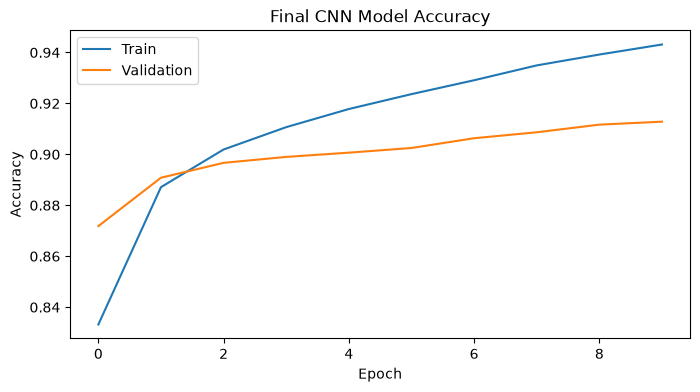

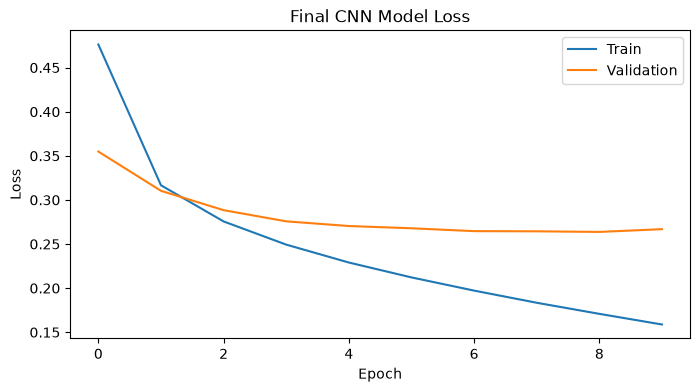

In [27]:
# Plot training and validation accuracy

plt.figure(figsize=(8, 4))

plt.plot(history_final.history['accuracy'], label='Train')
plt.plot(history_final.history['val_accuracy'], label='Validation')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Final CNN Model Accuracy')
plt.legend()
plt.show()
# Plot training and validation loss

plt.figure(figsize=(8, 4))

plt.plot(history_final.history['loss'], label='Train')
plt.plot(history_final.history['val_loss'], label='Validation')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Final CNN Model Loss')
plt.legend()
plt.show()

In [28]:
final_loss, final_accuracy = final_model.evaluate(
    X_test, y_test_cat, verbose=0
)

print(f"Final test loss: {final_loss:.3f}")
print(f"Final test accuracy: {final_accuracy * 100:.2f}%")
print(f"Improvement over baseline: {(final_accuracy - baseline_accuracy) * 100:.2f} percentage points")

Final test loss: 0.284
Final test accuracy: 90.49%
Improvement over baseline: 6.35 percentage points


Reflection: How does the final model's performance compare to the baseline and the CNN model? What do you think contributed to the final model's performance? If you had time, what other experiments would you run to further improve the model's performance?

**The final CNN model performed better than the baseline model, which achieved 84.14% test accuracy. The initial CNN achieved 90.23%, and the selected configuration with 32 filters and no dropout achieved 90.49% test accuracy during the controlled experiments.

I think the improvement mainly came from the convolutional layer, which can learn spatial features such as edges, shapes, and patterns from the images. Increasing the number of filters also slightly improved accuracy by allowing the model to learn more features. However, adding dropout did not improve accuracy in my experiments.

Looking at the final model's training curves, the training accuracy continued to increase while validation accuracy improved more slowly. Also, validation loss started to plateau during the later epochs, suggesting some overfitting.

If I had more time, I would experiment with different kernel sizes, additional convolutional layers, and smaller dropout rates. I would also try reducing the number of training epochs to see whether this could reduce overfitting and improve generalization.**

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.
### Submission Parameters:
* Submission Due Date: `23:59 PM - 11/09/2026`
* The branch name for your repo should be: `assignment-1`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_1.ipynb)
    * The Lab 1 notebook (labs/lab_1.ipynb)
    * The Lab 2 notebook (labs/lab_2.ipynb)
    * The Lab 3 notebook (labs/lab_3.ipynb)
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/deep_learning/pull/<pr_id>`
* Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.
Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.
If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at `#cohort-7-help-ml`. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.